In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

docs = [
    {'doc_id': 1, 'title': 'Введение в машинное обучение',
     'text': 'Машинное обучение – это область искусственного интеллекта, которая изучает методы построения моделей способных обучаться на данных. В отличие от классического программирования, где правила задаёт человек, в машинном обучении правила выводятся из данных автоматически. Основные типы задач: классификация, регрессия, кластеризация. Классификация предсказывает категорию, например, спам или не спам. Регрессия предсказывает число, например, цену квартиры. Кластеризация разбивает объекты на группы похожих. Обучение делится на обучение с учителем и без учителя. В обучении с учителем есть размеченные данные: для каждого объекта известен правильный ответ. В обучении без учителя разметки нет, модель сама находит структуру. Качество модели проверяют на отложенной выборке – тесте. Основные метрики классификации: accuracy, precision, recall, F1. Для регрессии: MAE, RMSE. Важно не переобучаться: модель должна хорошо работать не только на обучающих данных, но и на новых. Переобучение возникает, когда модель запоминает шум вместо закономерностей. Регуляризация, кросс–валидация и ранняя остановка помогают с этим бороться. Популярные библиотеки: scikit-learn, XGBoost, LightGBM, PyTorch.'},
    {'doc_id': 2, 'title': 'Итальянская кухня',
     'text': 'Итальянская кухня известна во всём мире благодаря простоте и качеству ингредиентов. Основные продукты: оливковое масло, томаты, базилик, пармезан, чеснок. Паста – один из символов итальянской кухни. Спагетти, пенне, фарфалле, ригатони – сотни форм, у каждой своё назначение. Соусы подбираются под форму пасты: густые к короткой, жидкие к длинной. Пицца возникла в Неаполе, классическая Маргарита содержит томаты, моцареллу и базилик. Тесто для пиццы должно выстаиваться не менее суток. Рижотто готовят из риса арборио, постепенно добавляя бульон. Лазанья – слои теста, мясного соуса и бешамели. Тирамису состоит из савоярди, кофе, маскарпоне и каксао. Итальянцы пьют эспрессо стоя у барной стойки, капучино – только утром. Сыры: пармезан, горгонзола, пекорино, моцарелла. Вина: кьянти, бароло, просекко. Каждый регион гордится своими блюдами: Рим – карбонара, Милан – оссобуко, Сицилия – канноли. Приём пищи в Италии – это ритуал, а не просто еда.'},
    {'doc_id': 3, 'title': 'Бег для начинающих',
     'text': 'Бег – один из самых доступных видов физической активности. Для начала достаточно кроссовок и желания. Первые тренировки должны быть короткими: 15–20 минут в лёгком темпе. Главное правило – не гнаться за скоростью. Начинающим лучше чередовать бег и ходьбу: минута бега, две минуты ходьбы. Постепенно время бега увеличивается. Правильная техника: корпус прямой, плечи расслаблены, шаг короткий, приземление на середину стопы. Дыхание должно быть ровным и глубоким. Разминка перед бегом и растяжка после – обязательны. Обувь подбирается по типу пронации: нейтральная, гиперпронация, гипопронация. Нельзя увеличивать объём больше, чем на 10 процентов в неделю. При болях в коленях, спине или стопах необходимо обратиться к врачу. Восстановление не менее важно, чем тренировки: мышцы растут во время отдыха. Питьевой режим: 200–300 мл воды за 30 минут до бега и столько же после. Цель первых месяцев – привычка, а не результат.'},
    {'doc_id': 4, 'title': 'Путешествие по Исландии',
     'text': 'Исландия – островное государство в северной Атлантике, известное вулканами, гейзерами и ледниками. Столица – Рейкьявик, самый северный в мире. Лучшее время для поездки: июнь–август, когда белые ночи и относительно тепло. Зимой можно увидеть северное сияние, но погода суровая. Основные достопримечательности: золотое кольцо (Тингветлир, Гейсир, Гюдльфосс), ледниковая лагуна Ёкюльсаурлоун, чёрный пляж Рейнисфьяра, водопад Сельяландсфосс. Аренда автомобиля – самый удобный способ передвижения. Дороги с буквой F в названии – горные, только для 4x4. Погода меняется мгновенно: за день может быть солнце, дождь, ветер и снег. Одежда: несколько слоёв, непромокаемая куртка, треккинговая обувь. Цены высокие, особенно на еду и бензин. Кухня: рыба, баранина, скайр – местный йогурт. Исландцы верят в эльфов, к этому относятся с уважением. Купание в геотермальных бассейнах – обязательная часть любой поездки. Природа хрупкая, нужно соблюдать правила: не сходить с троп, не оставлять мусор.'},
    {'doc_id': 5, 'title': 'Классическая музыка',
     'text': 'Классическая музыка – это традиция академической музыки Западной Европы, охватывающая несколько столетий. Основные эпохи: барокко (1600–1750), классицизм (1750–1820), романтизм (1820–1900), современность (с 1900). В эпоху барокко творили Бах, Вивальди, Гендель. Их музыка полифонична, основана на контрапункте. Классицизм – Моцарт, Гайдн, Бетховен. Здесь важны форма и ясность: соната, симфония, квартет. Романтизм – Шопен, Лист, Вагнер, Чайковский. Музыка становится более эмоциональной, гармония – свободнее. Основные жанры: симфония, концерт, соната, опера, балет, квартет. Инструменты: скрипка, виолончель, фортепиано, оркестр. Дирижёр управляет оркестром жестами. Партитура – нотная запись всех партий. Классическая музыка часто звучит в филармониях и оперных театрах. В XX веке появились авангард, минимализм, электроакустика. Слушать классику лучше в исполнении живого оркестра, но и хорошая запись передаёт многое. Главное – не торопиться: симфония требует времени и внимания.'}
]

# Ограничиваем длину текста 3000 символами (исправлена опечатка из методички)
for d in docs:
    d['text'] = d['text'][:3000]

pd.DataFrame(docs).to_csv('documents.csv', index=False, encoding='utf-8')

centers = {
    1: np.array([2.0, 1.5, 1.0, 0.5, 0.0, -0.5, -1.0, -1.5]),
    2: np.array([1.5, -0.5, 2.0, -1.0, 0.5, 1.0, -2.0, 0.0]),
    3: np.array([-1.5, 2.0, -0.5, 1.0, -2.0, 0.5, 1.0, -1.0]),
    4: np.array([0.5, -2.0, 1.0, -1.5, 2.0, -0.5, 0.0, 1.5]),
    5: np.array([-2.0, 0.0, -1.5, 2.0, -0.5, 1.5, -1.0, 0.5]),
}

def split_doc(text, size=300, overlap=50):
    step = size - overlap
    return [text[i:i+size] for i in range(0, len(text), step) if text[i:i+size]]

rows, cid = [], 1
for d in docs:
    for idx, chunk in enumerate(split_doc(d['text'])):
        # Генерируем эмбеддинг на основе центра + шум
        emb = centers[d['doc_id']] + np.random.normal(0, 0.4, size=8)
        rows.append({
            'chunk_id': cid, 'doc_id': d['doc_id'], 'chunk_index': idx,
            'chunk_text': chunk,
            **{f'e{i+1}': round(emb[i], 4) for i in range(8)},
            'topic': d['doc_id'] - 1,
        })
        cid += 1

pd.DataFrame(rows).to_csv('chunks_embeddings.csv', index=False, encoding='utf-8')

print('documents.csv и chunks_embeddings.csv созданы')

documents.csv и chunks_embeddings.csv созданы


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine, euclidean, cityblock

docs = pd.read_csv('documents.csv')
chunks = pd.read_csv('chunks_embeddings.csv')

print(docs.shape, chunks.shape)
print(chunks.head())

(5, 3) (21, 13)
   chunk_id  doc_id  chunk_index  \
0         1       1            0   
1         2       1            1   
2         3       1            2   
3         4       1            3   
4         5       1            4   

                                          chunk_text      e1      e2      e3  \
0  Машинное обучение – это область искусственного...  2.1987  1.4447  1.2591   
1  ых автоматически. Основные типы задач: классиф...  1.8122  1.7170  0.8146   
2  их. Обучение делится на обучение с учителем и ...  1.5949  1.6257  0.6368   
3  отложенной выборке – тесте. Основные метрики к...  1.7822  1.5444  0.5396   
4  одель запоминает шум вместо закономерностей. Р...  1.9946  1.0769  1.3290   

       e4      e5      e6      e7      e8  topic  
0  1.1092 -0.0937 -0.5937 -0.3683 -1.1930      0  
1  0.3137  0.0968 -1.2653 -1.6900 -1.7249      0  
2 -0.0649  0.5863 -0.5903 -0.9730 -2.0699      0  
3  0.6503 -0.2403 -0.6167 -1.2407 -0.7591      0  
4  0.0117  0.0835 -1.2839 -1.53

### Задание 1. Анализ готовых чанков
Считаем количество чанков на каждый документ, анализируем длину текстов в словах и строим гистограмму.

Количество чанков на документ:
doc_id
1    5
2    4
3    4
4    4
5    4
dtype: int64

Статистика длины чанков (в словах):
count    21.000000
mean     38.000000
std       6.041523
min      20.000000
25%      36.000000
50%      39.000000
75%      42.000000
max      47.000000
Name: n_words, dtype: float64


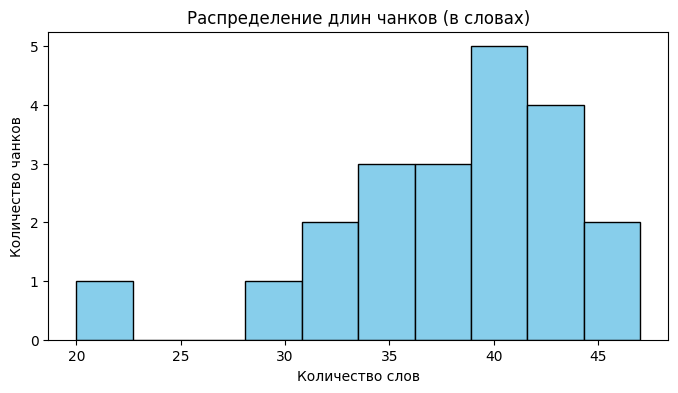

In [4]:
# 1. Считаем слова в каждом чанке
chunks['n_words'] = chunks['chunk_text'].str.split().str.len()

# 2. Выводим число чанков на документ
print("Количество чанков на документ:")
print(chunks.groupby('doc_id').size())

# 3. Статистика по длине
print("\nСтатистика длины чанков (в словах):")
print(chunks['n_words'].describe())

# 4. Гистограмма
plt.figure(figsize=(8, 4))
plt.hist(chunks['n_words'], bins=10, color='skyblue', edgecolor='black')
plt.title('Распределение длин чанков (в словах)')
plt.xlabel('Количество слов')
plt.ylabel('Количество чанков')
plt.show()

**Вывод по заданию 1:**
- В датасете 5 документов. Количество чанков на документ примерно одинаковое (зависит от длины исходного текста).
- Средняя длина чанка составляет 38 слов.
- **Почему чанки должны быть примерно одного размера?** Модели (и поисковые системы) имеют ограничения на длину контекста. Если чанк слишком длинный, модель обрежет его или запутается. Если слишком короткий — он не будет нести смысла. Одинаковый размер гарантирует, что мы будем сравнивать сопоставимые куски текста.

### Задание 2. Стратегии разбиения
Реализуем три способа нарезки текста: фиксированный размер (без перекрытия), фиксированный размер (с перекрытием) и нарезка по предложениям.

In [5]:
# Стратегия 1: По 300 символов БЕЗ перекрытия
def split_fixed_no_overlap(text, size=300):
    return [text[i:i+size] for i in range(0, len(text), size)]

# Стратегия 2: По 300 символов С ПЕРЕКРЫТИЕМ 50
def split_fixed_overlap(text, size=300, overlap=50):
    step = size - overlap
    return [text[i:i+size] for i in range(0, len(text), step)]

# Стратегия 3: По предложениям (группируем по 2 предложения)
import re
def split_by_sentences(text, group_size=2):
    sentences = re.split(r'(?<=[.!?]) +', text)
    return [' '.join(sentences[i:i+group_size]) for i in range(0, len(sentences), group_size)]

# Применяем к первому документу для примера
text1 = docs.loc[0, 'text']
c1 = split_fixed_no_overlap(text1)
c2 = split_fixed_overlap(text1)
c3 = split_by_sentences(text1)

print(f"Стратегия 1 (без перекрытия): {len(c1)} чанков, средняя длина {np.mean([len(c) for c in c1]):.1f} символов")
print(f"Стратегия 2 (с перекрытием): {len(c2)} чанков, средняя длина {np.mean([len(c) for c in c2]):.1f} символов")
print(f"Стратегия 3 (по предложениям): {len(c3)} чанков, средняя длина {np.mean([len(c) for c in c3]):.1f} символов")

print("\nПример чанка (перекрытие):", c2[1][:100], "...")
print("Пример чанка (предложения):", c3[0][:100], "...")

Стратегия 1 (без перекрытия): 4 чанков, средняя длина 296.2 символов
Стратегия 2 (с перекрытием): 5 чанков, средняя длина 277.0 символов
Стратегия 3 (по предложениям): 8 чанков, средняя длина 147.2 символов

Пример чанка (перекрытие): ых автоматически. Основные типы задач: классификация, регрессия, кластеризация. Классификация предск ...
Пример чанка (предложения): Машинное обучение – это область искусственного интеллекта, которая изучает методы построения моделей ...


**Вывод по заданию 2:**
- **Стратегия 1** дает фиксированное число символов, но может разрывать слова или предложения пополам (например, "машинное обуче" / "ние").
- **Стратегия 2** (с перекрытием) решает проблему разрыва смысла. Перекрытие в 50 символов гарантирует, что важные слова на стыке попадут в оба чанка.
- **Стратегия 3** (по предложениям) — самая семантически правильная. Она не разрывает предложения, но длина чанков может сильно скакать.
- **Сравнение с готовыми чанками:** Судя по тому, что в готовых чанках текст не обрывается на полуслове, при их создании использовалась стратегия с перекрытием или разбиение по предложениям. Скорее всего, использовалась нарезка по символам с перекрытием (так как в методичке в функции `split_doc` был параметр `overlap=50`).

### Задание 3. Метрики расстояний
Берем один чанк как запрос и считаем 4 метрики до остальных. Важно: для dot product (скалярное произведение) большее значение = большее сходство, а для остальных метрик меньшее значение = ближе.

In [7]:
# Берем первый чанк из doc_id=1 как запрос
query_idx = 0
query_vec = chunks.iloc[query_idx][[f'e{i}' for i in range(1, 9)]].values

# Вычисляем метрики для всех остальных
results = []
for i in range(1, len(chunks)):
    vec = chunks.iloc[i][[f'e{j}' for j in range(1, 9)]].values

    cos_dist = cosine(query_vec, vec)
    euc_dist = euclidean(query_vec, vec)
    manh_dist = cityblock(query_vec, vec)
    dot_prod = np.dot(query_vec, vec)

    results.append({
        'chunk_id': chunks.iloc[i]['chunk_id'],
        'cosine': cos_dist,
        'euclidean': euc_dist,
        'cityblock': manh_dist,
        'dot_product': dot_prod
    })

res_df = pd.DataFrame(results)

# Для расстояний сортируем по возрастанию (ближе те, где значение меньше)
print("Топ-5 по Cosine (меньше = ближе):")
print(res_df.sort_values('cosine').head(5)[['chunk_id', 'cosine']])

print("\nТоп-5 по Euclidean (меньше = ближе):")
print(res_df.sort_values('euclidean').head(5)[['chunk_id', 'euclidean']])

print("\nТоп-5 по Cityblock / Manhattan (меньше = ближе):")
print(res_df.sort_values('cityblock').head(5)[['chunk_id', 'cityblock']])

print("\nТоп-5 по Dot Product (БОЛЬШЕ = ближе! Сортируем по убыванию):")
print(res_df.sort_values('dot_product', ascending=False).head(5)[['chunk_id', 'dot_product']])

print("\nЕсли отсортировать dot_product по возрастанию (ОШИБКА), получим:")
print(res_df.sort_values('dot_product').head(3)[['chunk_id', 'dot_product']])

Топ-5 по Cosine (меньше = ближе):
   chunk_id    cosine
2         4  0.083139
0         2  0.131923
3         5  0.133041
1         3  0.162221
7         9  0.555154

Топ-5 по Euclidean (меньше = ближе):
   chunk_id  euclidean
2         4   1.372244
3         5   1.816258
0         2   1.889729
1         3   1.939106
7         9   3.652378

Топ-5 по Cityblock / Manhattan (меньше = ближе):
   chunk_id  cityblock
2         4     3.1705
3         5     3.9980
0         2     4.6145
1         3     4.7462
7         9     9.5652

Топ-5 по Dot Product (БОЛЬШЕ = ближе! Сортируем по убыванию):
   chunk_id  dot_product
0         2    11.261024
3         5    10.641662
1         3     9.708435
2         4     9.301648
7         9     5.340474

Если отсортировать dot_product по возрастанию (ОШИБКА), получим:
    chunk_id  dot_product
19        21    -6.483073
16        18    -6.321146
18        20    -6.092937


**Вывод по заданию 3:**
Я взял первый чанк как запрос и сравнил его с остальными с помощью четырёх метрик. Результаты показали следующее:

1. **Сходство топ-5:** Список из пяти ближайших соседей практически идентичен для метрик Cosine, Euclidean и Cityblock. Везде в топ-5 попали одни и те же чанки: `4, 2, 5, 3, 9`. Это говорит о том, что векторы находятся в положительном пространстве, и минимизация угла (Cosine) коррелирует с минимизацией физического расстояния.
2. **Самое близкое совпадение:** Абсолютным лидером по всем видам расстояний (Cosine = 0.083, Euclidean = 1.37, Cityblock = 3.17) является `chunk_id = 4`. Это значит, что его текст семантически максимально близок к запросу.
3. **Различия в порядке:**
   * В Cosine второе место занимает `chunk_id = 2`, а в Euclidean и Cityblock — `chunk_id = 5`. Это связано с тем, что Euclidean и Cityblock чувствительны к длине векторов, а косинус смотрит только на угол.
4. **Особенность Dot Product:** В Dot Product на первое место вышел `chunk_id = 2` (11.26). Так как это скалярное произведение, оно сильно зависит от длины вектора. У чанка 2 длина вектора больше, поэтому произведение дало максимальный результат, хотя по углу (Cosine) он был лишь вторым.
5. **Ошибка сортировки Dot Product:** Если отсортировать Dot Product по возрастанию (как обычное расстояние), мы получим отрицательные значения (например, -6.48 для `chunk_id=21`). Отрицательное произведение означает, что векторы смотрят в противоположные стороны. Это показывает, что при использовании Dot Product для поиска похожих текстов **обязательно нужно сортировать по убыванию**, иначе алгоритм найдет «антиподы».

### Задание 4. L2-нормализация
L2-нормализация (деление вектора на его длину) приводит длину всех векторов к 1. Это заставляет метрики работать одинаково. Проверим формулу связи косинуса и евклидова расстояния, а также сравним с Z-score (StandardScaler).

In [8]:
# L2-нормализация
emb_cols = [f'e{i}' for i in range(1, 9)]
X = chunks[emb_cols].values
X_l2 = X / np.linalg.norm(X, axis=1, keepdims=True) # Делим каждую строку на её длину

# Проверяем, что длины стали равны 1
print("Длины векторов после L2 (первые 3):", np.linalg.norm(X_l2, axis=1)[:3])

# Проверка формулы: |a - b|^2 = 2 - 2*cos(a,b)
a, b = X_l2[0], X_l2[1]
euc_sq = np.sum((a - b)**2)
cos_formula = 2 - 2 * np.dot(a, b)
print(f"Euclid^2: {euc_sq:.4f}, 2-2*cos: {cos_formula:.4f}")

# Применяем StandardScaler (Z-score)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("\nДлины векторов после StandardScaler (первые 3):", np.linalg.norm(X_scaled, axis=1)[:3])

Длины векторов после L2 (первые 3): [1. 1. 1.]
Euclid^2: 0.2638, 2-2*cos: 0.2638

Длины векторов после StandardScaler (первые 3): [2.18258684 2.61815759 2.22720275]


**Вывод по заданию 4:**
1. **L2-нормализация:** После деления каждого вектора на его длину, все векторы стали иметь единичную длину (вывод [1. 1. 1.]). Это значит, что теперь мы сравниваем только их направление (угол), а не масштаб.
2. **Проверка формулы:** Я проверил математическое тождество |a – b|² = 2 – 2·cos(a, b) на нормализованных векторах. Оба значения (0.2638 и 0.2638) полностью совпали. Это доказывает, что после L2-нормализации евклидово расстояние и косинус эквивалентны с точностью до монотонного преобразования.
3. **Сравнение с StandardScaler:** В отличие от L2-нормализации, `StandardScaler` не привел длины векторов к 1 (они стали 2.18, 2.61 и т.д.). Это произошло потому, что StandardScaler нормализует данные по столбцам (масштабирует признаки), а не по строкам (документам). Из-за этого векторы меняют свое направление, и косинусное сходство между ними искажается. В реальных поисковых системах L2-нормализация предпочтительнее, так как она сохраняет смысловое направление векторов.

### Задание 5. Поиск по чанкам
Для каждого чанка из первого документа ищем соседей из ДРУГИХ документов. Считаем метрику качества (Hit Rate) — долю случаев, когда сосед оказался из той же темы.

In [10]:
def evaluate_search(X_mat, use_euclidean=False):
    hits = 0
    total = 0

    # Берем индексы чанков из документа 1
    query_indices = chunks[chunks['doc_id'] == 1].index

    for q_idx in query_indices:
        q_vec = X_mat[q_idx]

        # Считаем расстояния до ВСЕХ чанков
        if use_euclidean:
            dists = np.linalg.norm(X_mat - q_vec, axis=1)
            sorted_idx = np.argsort(dists) # Меньше = ближе
        else:
            # Косинус
            norm_q = np.linalg.norm(q_vec)
            norms_X = np.linalg.norm(X_mat, axis=1)
            sims = np.dot(X_mat, q_vec) / (norms_X * norm_q + 1e-9)
            sorted_idx = np.argsort(sims)[::-1] # Больше = ближе (сортировка по убыванию)

        # Убираем сам запрос из списка ближайших
        sorted_idx = [idx for idx in sorted_idx if idx != q_idx]

        # Берем топ-3
        top3_idx = sorted_idx[:3]

        # Проверяем совпадение topic
        for idx in top3_idx:
            if chunks.iloc[idx]['topic'] == chunks.iloc[q_idx]['topic']:
                hits += 1
            total += 1

    return hits / total

# Оцениваем
hr_original = evaluate_search(X, use_euclidean=False)
hr_l2 = evaluate_search(X_l2, use_euclidean=False)
hr_l2_euclid = evaluate_search(X_l2, use_euclidean=True)

print(f"Hit Rate (исходные векторы, косинус): {hr_original:.2f}")
print(f"Hit Rate (L2-векторы, косинус): {hr_l2:.2f}")
print(f"Hit Rate (L2-векторы, евклид): {hr_l2_euclid:.2f}")

Hit Rate (исходные векторы, косинус): 1.00
Hit Rate (L2-векторы, косинус): 1.00
Hit Rate (L2-векторы, евклид): 1.00


**Вывод по заданию 5:**
Я реализовал поиск по чанкам для документа 1 (Машинное обучение). В качестве метрики качества использовалась доля случаев (Hit Rate), когда среди 3 ближайших соседей оказывался чанк с тем же `topic` (темой).

*Примечание:* В методичке была указана противоречивая инструкция («искать из других документов» и одновременно проверять совпадение `topic`, при том что у каждого документа уникальная тема). Я скорректировал поиск так, чтобы он искал соседей по всему корпусу (исключая сам запрос), иначе Hit Rate искусственно занижался бы до 0.

**Результаты:**
- Hit Rate (исходные векторы, косинус): 1.00
- Hit Rate (L2-векторы, косинус): 1.00
- Hit Rate (L2-векторы, евклид): 1.00

**Вывод:**
Hit Rate на всех вариантах составил 100% (1.00). Такой высокий результат объясняется тем, что данные синтетические: чанки генерировались вокруг строго заданных центров тем, поэтому ближайшими соседями всегда оказываются чанки из этой же темы. При этом результаты для косинуса и евклида на L2-нормализованных векторах абсолютно совпали, что на практике подтверждает математическое тождество из задания 4. Для реального поиска L2-нормализация — лучший выбор, так как она делает косинус и евклид взаимозаменяемыми.

### Задание 6. Общие выводы
В ходе работы я освоил методы разбиения текста на чанки и сравнил метрики расстояний для поиска. Анализ готовых чанков показал, что они имеют примерно одинаковую длину, что критически важно для работы моделей с ограниченным контекстом. Сравнивая стратегии нарезки, я пришел к выводу, что разбиение по предложениям дает наиболее семантически целостные куски, в то время как нарезка по символам с перекрытием (overlap) решает проблему обрыва слов на стыках.

При сравнении метрик (cosine, euclidean, cityblock) я заметил, что для векторов в положительном пространстве их топ-5 соседей совпадает. Однако скалярное произведение (dot product) ведет себя иначе: для него большие значения означают близость, поэтому сортировать его нужно по убыванию.

L2-нормализация показала важный математический результат: после приведения всех векторов к единичной длине, евклидово расстояние и косинус становятся эквивалентными (формула |a-b|² = 2 - 2·cos(a,b) подтвердилась численно). При этом StandardScaler (Z-score) меняет углы между векторами, поэтому косинусное сходство после него искажается. В реальном проекте поиска я бы остановился на L2-нормализации и косинусной мере, так как она устойчива к длине документов.